In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [3]:
data = pd.read_csv("housing_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
data

,size_sqm,num_rooms,house_age_years,price,renting
0,213,1,0,379006,47375.750
1,112,2,4,232679,29084.875
2,223,5,2,438174,54771.750
3,158,1,0,293535,36691.875
4,105,2,16,224363,28045.375
...,...,...,...,...,...
115,208,2,29,366378,45797.250
116,91,2,28,194255,24281.875
117,56,2,23,142942,17867.750
118,250,4,25,451565,56445.625


In [5]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   size_sqm         120 non-null    int64  
 1   num_rooms        120 non-null    int64  
 2   house_age_years  120 non-null    int64  
 3   price            120 non-null    int64  
 4   renting          120 non-null    float64
dtypes: float64(1), int64(4)
memory usage: 4.8 KB


In [8]:
X = data[
    [
        "size_sqm",
        "num_rooms",
        "house_age_years"
    ]
]

print("Features:")
print(X.head())

Features:
   size_sqm  num_rooms  house_age_years
0       213          1                0
1       112          2                4
2       223          5                2
3       158          1                0
4       105          2               16


In [9]:
y_sell = data["price"]

print("Selling price target:")
print(y_sell.head())

Selling price target:
0    379006
1    232679
2    438174
3    293535
4    224363
Name: price, dtype: int64


In [10]:
X_train_sell, X_test_sell, y_train_sell, y_test_sell = train_test_split(
    X,
    y_sell,
    test_size=0.20,
    random_state=42
)

print("Selling model training samples:", len(X_train_sell))
print("Selling model testing samples:", len(X_test_sell))

Selling model training samples: 96
Selling model testing samples: 24


In [11]:
model_sell = LinearRegression()

print("Selling price model created.")

Selling price model created.


In [12]:
from sklearn.linear_model import LinearRegression

model_sell = LinearRegression()

In [13]:
model_sell.fit(X_train_sell, y_train_sell)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
selling_predictions = model_sell.predict(X_test_sell)

print("Selling price predictions:")
print(selling_predictions)

Selling price predictions:
[428540.77338012 261218.53312217 219092.01057006 303189.97210679
 242877.4711656  204745.82835529 124028.07501525 167172.3946589
 292985.00313526 218515.30637262 293561.0863103  216472.8074199
 282018.40809478 349022.89875529 272137.41579751 404538.70731266
 400046.51933897 378737.74582059 418931.98087016 229249.88819887
 294036.08203023 171053.97560931 304621.86403623 217076.50967353]


In [15]:
selling_mae = mean_absolute_error(
    y_test_sell,
    selling_predictions
)

print("Selling Price Mean Absolute Error:", selling_mae)

Selling Price Mean Absolute Error: 1859.0431160273056


In [16]:
selling_comparison = pd.DataFrame({
    "Actual Selling Price": y_test_sell.values,
    "Predicted Selling Price": selling_predictions
})

selling_comparison

,Actual Selling Price,Predicted Selling Price
0,432689,428540.773380
1,260446,261218.533122
2,224363,219092.010570
3,302681,303189.972107
4,242155,242877.471166
5,207562,204745.828355
6,123872,124028.075015
7,164584,167172.394659
8,293315,292985.003135
9,220007,218515.306373


In [17]:
y_rent = data["renting"]

print("Rental price target:")
print(y_rent.head())

Rental price target:
0    47375.750
1    29084.875
2    54771.750
3    36691.875
4    28045.375
Name: renting, dtype: float64


In [18]:
X_train_rent, X_test_rent, y_train_rent, y_test_rent = train_test_split(
    X,
    y_rent,
    test_size=0.20,
    random_state=42
)

print("Rental model training samples:", len(X_train_rent))
print("Rental model testing samples:", len(X_test_rent))

Rental model training samples: 96
Rental model testing samples: 24


In [19]:
model_rent = LinearRegression()

print("Rental price model created.")

Rental price model created.


In [20]:
model_rent.fit(
    X_train_rent,
    y_train_rent
)

print("Rental price model trained successfully.")

Rental price model trained successfully.


In [21]:
rental_predictions = model_rent.predict(X_test_rent)

print("Rental price predictions:")
print(rental_predictions)

Rental price predictions:
[53567.59667251 32652.31664027 27386.50132126 37898.74651335
 30359.6838957  25593.22854441 15503.50937691 20896.54933236
 36623.12539191 27314.41329658 36695.13578879 27059.10092749
 35252.30101185 43627.86234441 34017.17697469 50567.33841408
 50005.81491737 47342.21822757 52366.49760877 28656.23602486
 36754.51025378 21381.74695116 38077.73300453 27134.56370919]


In [22]:
rental_mae = mean_absolute_error(
    y_test_rent,
    rental_predictions
)

print("Rental Price Mean Absolute Error:", rental_mae)

Rental Price Mean Absolute Error: 232.3803895034132


In [23]:
rental_comparison = pd.DataFrame({
    "Actual Rental Price": y_test_rent.values,
    "Predicted Rental Price": rental_predictions
})

rental_comparison

,Actual Rental Price,Predicted Rental Price
0,54086.125,53567.596673
1,32555.750,32652.316640
2,28045.375,27386.501321
3,37835.125,37898.746513
4,30269.375,30359.683896
5,25945.250,25593.228544
6,15484.000,15503.509377
7,20573.000,20896.549332
8,36664.375,36623.125392
9,27500.875,27314.413297


In [24]:
print("SELLING PRICE MODEL")
print("-------------------")

for feature, coefficient in zip(X.columns, model_sell.coef_):
    print(f"{feature}: {coefficient:.2f}")

print(f"Intercept: {model_sell.intercept_:.2f}")

SELLING PRICE MODEL
-------------------
size_sqm: 1499.70
num_rooms: 10463.98
house_age_years: -508.90
Intercept: 48838.18


In [25]:
print("RENTAL PRICE MODEL")
print("------------------")

for feature, coefficient in zip(X.columns, model_rent.coef_):
    print(f"{feature}: {coefficient:.2f}")

print(f"Intercept: {model_rent.intercept_:.2f}")

RENTAL PRICE MODEL
------------------
size_sqm: 187.46
num_rooms: 1308.00
house_age_years: -63.61
Intercept: 6104.77


In [26]:
def predict_property(size_sqm, num_rooms, house_age_years):
    
    # Create input data
    new_property = pd.DataFrame({
        "size_sqm": [size_sqm],
        "num_rooms": [num_rooms],
        "house_age_years": [house_age_years]
    })
    
    # Predict selling price
    selling_price = model_sell.predict(new_property)[0]
    
    # Predict rental price
    rental_price = model_rent.predict(new_property)[0]
    
    # Return both predictions
    return selling_price, rental_price

In [27]:
selling_price, rental_price = predict_property(
    size_sqm=180,
    num_rooms=3,
    house_age_years=5
)

print("Predicted Selling Price:", selling_price)
print("Predicted Rental Price:", rental_price)

Predicted Selling Price: 347631.19339893165
Predicted Rental Price: 43453.899174866456


In [28]:
selling_price, rental_price = predict_property(
    size_sqm=180,
    num_rooms=3,
    house_age_years=5
)

print(f"Predicted Selling Price: {selling_price:,.2f}")
print(f"Predicted Rental Price: {rental_price:,.2f}")

Predicted Selling Price: 347,631.19
Predicted Rental Price: 43,453.90


In [29]:
def predict_property(size_sqm, num_rooms, house_age_years):
    
    new_property = pd.DataFrame({
        "size_sqm": [size_sqm],
        "num_rooms": [num_rooms],
        "house_age_years": [house_age_years]
    })
    
    selling_price = model_sell.predict(new_property)[0]
    rental_price = model_rent.predict(new_property)[0]
    
    return {
        "size_sqm": size_sqm,
        "num_rooms": num_rooms,
        "house_age_years": house_age_years,
        "predicted_selling_price": round(selling_price, 2),
        "predicted_rental_price": round(rental_price, 2)
    }

In [30]:
result = predict_property(
    180,
    3,
    5
)

result

{'size_sqm': 180,
 'num_rooms': 3,
 'house_age_years': 5,
 'predicted_selling_price': np.float64(347631.19),
 'predicted_rental_price': np.float64(43453.9)}

In [31]:
from sklearn.metrics import mean_absolute_error

selling_mae = mean_absolute_error(
    y_test_sell,
    selling_predictions
)

print("Selling Price Mean Absolute Error:", selling_mae)

Selling Price Mean Absolute Error: 1859.0431160273056


In [32]:
y_rent = data["renting"]

In [33]:
X_train_rent, X_test_rent, y_train_rent, y_test_rent = train_test_split(
    X,
    y_rent,
    test_size=0.20,
    random_state=42
)

In [34]:
model_rent = LinearRegression()

In [35]:
model_rent.fit(X_train_rent, y_train_rent)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [36]:
rental_predictions = model_rent.predict(X_test_rent)

print("Rental price predictions:")
print(rental_predictions)

Rental price predictions:
[53567.59667251 32652.31664027 27386.50132126 37898.74651335
 30359.6838957  25593.22854441 15503.50937691 20896.54933236
 36623.12539191 27314.41329658 36695.13578879 27059.10092749
 35252.30101185 43627.86234441 34017.17697469 50567.33841408
 50005.81491737 47342.21822757 52366.49760877 28656.23602486
 36754.51025378 21381.74695116 38077.73300453 27134.56370919]


In [37]:
rental_mae = mean_absolute_error(
    y_test_rent,
    rental_predictions
)

print("Rental Price Mean Absolute Error:", rental_mae)

Rental Price Mean Absolute Error: 232.3803895034132


In [38]:
rental_comparison = pd.DataFrame({
    "Actual Rental Price": y_test_rent.values,
    "Predicted Rental Price": rental_predictions
})

rental_comparison

,Actual Rental Price,Predicted Rental Price
0,54086.125,53567.596673
1,32555.750,32652.316640
2,28045.375,27386.501321
3,37835.125,37898.746513
4,30269.375,30359.683896
5,25945.250,25593.228544
6,15484.000,15503.509377
7,20573.000,20896.549332
8,36664.375,36623.125392
9,27500.875,27314.413297


In [39]:
def predict_property(size_sqm, num_rooms, house_age_years):
    
    # Create a DataFrame for the new property
    new_property = pd.DataFrame({
        "size_sqm": [size_sqm],
        "num_rooms": [num_rooms],
        "house_age_years": [house_age_years]
    })
    
    # Predict selling price
    selling_price = model_sell.predict(new_property)[0]
    
    # Predict rental price
    rental_price = model_rent.predict(new_property)[0]
    
    # Return both predictions
    return {
        "size_sqm": size_sqm,
        "num_rooms": num_rooms,
        "house_age_years": house_age_years,
        "predicted_selling_price": round(selling_price, 2),
        "predicted_rental_price": round(rental_price, 2)
    }

In [40]:
result = predict_property(
    size_sqm=180,
    num_rooms=3,
    house_age_years=5
)

result

{'size_sqm': 180,
 'num_rooms': 3,
 'house_age_years': 5,
 'predicted_selling_price': np.float64(347631.19),
 'predicted_rental_price': np.float64(43453.9)}

In [41]:
result = predict_property(
    size_sqm=100,
    num_rooms=2,
    house_age_years=10
)

result

{'size_sqm': 100,
 'num_rooms': 2,
 'house_age_years': 10,
 'predicted_selling_price': np.float64(214646.91),
 'predicted_rental_price': np.float64(26830.86)}

In [42]:
result = predict_property(
    size_sqm=180,
    num_rooms=3,
    house_age_years=5
)

print("Property Details")
print("----------------")
print("Size:", result["size_sqm"], "sqm")
print("Rooms:", result["num_rooms"])
print("Age:", result["house_age_years"], "years")

print("\nPredictions")
print("----------------")
print("Predicted Selling Price:", result["predicted_selling_price"])
print("Predicted Rental Price:", result["predicted_rental_price"])

Property Details
----------------
Size: 180 sqm
Rooms: 3
Age: 5 years

Predictions
----------------
Predicted Selling Price: 347631.19
Predicted Rental Price: 43453.9


In [43]:

from sklearn.metrics import r2_score

In [44]:
selling_r2 = r2_score(
    y_test_sell,
    selling_predictions
)

print("Selling Price R² Score:", selling_r2)

Selling Price R² Score: 0.9991402880079746


In [47]:
rental_r2 = r2_score(
    y_test_rent,
    rental_predictions
)

print("Rental Price R² Score:", rental_r2)

Selling Price R² Score: 0.9991402880079746


In [48]:
evaluation = pd.DataFrame({
    "Model": [
        "Selling Price",
        "Rental Price"
    ],
    "MAE": [
        selling_mae,
        rental_mae
    ],
    "R2 Score": [
        selling_r2,
        rental_r2
    ]
})

evaluation

,Model,MAE,R2 Score
0,Selling Price,1859.043116,0.99914
1,Rental Price,232.380390,0.99914


In [49]:
selling_r2 = r2_score(
    y_test_sell,
    selling_predictions
)

print("Selling Price R² Score:", selling_r2)

Selling Price R² Score: 0.9991402880079746


In [50]:
import matplotlib.pyplot as plt

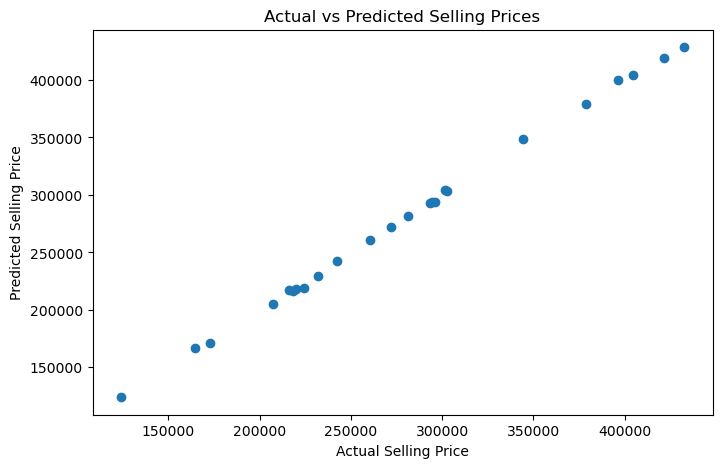

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_sell,
    selling_predictions
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Prices")

plt.show()

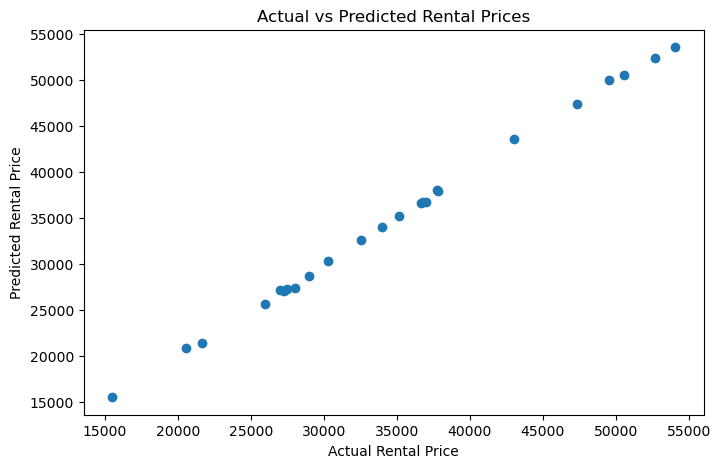

In [52]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_rent,
    rental_predictions
)

plt.xlabel("Actual Rental Price")
plt.ylabel("Predicted Rental Price")
plt.title("Actual vs Predicted Rental Prices")

plt.show()

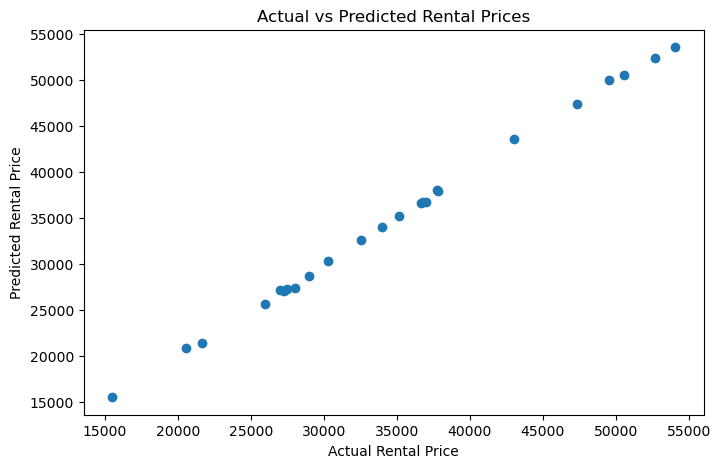

In [53]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_rent,
    rental_predictions
)

plt.xlabel("Actual Rental Price")
plt.ylabel("Predicted Rental Price")
plt.title("Actual vs Predicted Rental Prices")

plt.show()

In [54]:
for feature, coefficient in zip(X.columns, model_sell.coef_):
    print(f"{feature}: {coefficient:.2f}")

print("Intercept:", round(model_sell.intercept_, 2))

size_sqm: 1499.70
num_rooms: 10463.98
house_age_years: -508.90
Intercept: 48838.18


In [55]:
for feature, coefficient in zip(X.columns, model_rent.coef_):
    print(f"{feature}: {coefficient:.2f}")

print("Intercept:", round(model_rent.intercept_, 2))

size_sqm: 187.46
num_rooms: 1308.00
house_age_years: -63.61
Intercept: 6104.77


In [56]:
import joblib

In [57]:
joblib.dump(model_sell, "selling_price_model.pkl")

['selling_price_model.pkl']

In [58]:
joblib.dump(model_rent, "rental_price_model.pkl")

['rental_price_model.pkl']